# Jin et al. single-cell DEA aging with EdgeR
Primary pseudobulk eligibility is determined at the **donor × subclass** level using `MIN_CELLS = 15`. To match the spatial analysis, subclasses must have at least `MIN_DONORS = 2` donors in each age group. No additional minimum pseudobulk library-count threshold is applied. Gene filtering and edgeR testing are matched to the spatial workflow: `filterByExpr(min.count = 2)`, TMM normalization, `estimateGLMRobustDisp()`, `glmFit()`, and `glmLRT()`.

## 1. Imports and load processed count data

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy.sparse as sp
from scipy.stats import mannwhitneyu
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import gc

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
import importlib.metadata

In [2]:
# Set this directory to the location of the cleaned Jin count data.
DATA_DIR = Path("/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data")
INPUT_FILE = DATA_DIR / "adata_cleaned_int32.h5ad"
outdir = DATA_DIR / "pseudobulk_primary"
RESULT_DIR = DATA_DIR / "edgeR_results"
MIN_CELLS = 15
MIN_DONORS = 2
major_subclasses = ["Endo NN", "Microglia NN", "Astro-NT NN", "OPC NN", "Oligo NN"]
for directory in (outdir, RESULT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

In [3]:
adata = sc.read_h5ad(
    INPUT_FILE
)

print(adata)
print("X dtype:", adata.X.dtype)
print("Sparse:", sp.issparse(adata.X))
print("Format:", adata.X.getformat())

AnnData object with n_obs × n_vars = 1161340 × 32285
    obs: 'class_label', 'subclass_label', 'supertype_label', 'cluster_label', 'library_prep', 'broad_roi', 'roi', 'sex', 'age_cat', 'external_donor_name', 'facs_population_plan', 'gene.counts.0', 'doublet_score', 'umi.counts', 'pct_counts_mt', 'log1p_total_counts', 'log1p_n_genes_by_counts', 'outlier', 'mt_outlier'
    obsm: 'X_umap'
    layers: None (.X)
X dtype: int32
Sparse: True
Format: csr


## 2. Validate count metadata against the count matrix

In [4]:
n_genes_from_X = np.diff(adata.X.indptr)

print(
    "gene.counts.0 matches X:",
    np.array_equal(
        n_genes_from_X,
        adata.obs["gene.counts.0"].to_numpy()
    )
)

gene.counts.0 matches X: True


In [5]:
rng = np.random.default_rng(42)

idx = rng.choice(
    adata.n_obs,
    size=1000,
    replace=False
)

matrix_umi = np.asarray(
    adata.X[idx].sum(axis=1)
).ravel()

stored_umi = adata.obs["umi.counts"].to_numpy()[idx]

print(
    "umi.counts matches X:",
    np.array_equal(matrix_umi, stored_umi)
)

print(
    "Maximum difference:",
    np.max(np.abs(matrix_umi - stored_umi))
)

umi.counts matches X: True
Maximum difference: 0


In [6]:
adata.obs["n_genes_by_counts"] = (
    adata.obs["gene.counts.0"].astype(np.int32)
)

adata.obs["total_counts"] = (
    adata.obs["umi.counts"].astype(np.int32)
)

## 3. Cell-level QC metrics and diagnostic flags

These flags are retained for QC reporting and sensitivity analysis. They do **not** define the primary-analysis cell set.

In [7]:
mt_mask = (
    adata.var_names
    .str.upper()
    .str.startswith("MT-")
)

print(
    "Number of mitochondrial genes:",
    mt_mask.sum()
)

print(
    adata.var_names[mt_mask].tolist()
)

Number of mitochondrial genes: 13
['mt-Nd1', 'mt-Nd2', 'mt-Co1', 'mt-Co2', 'mt-Atp8', 'mt-Atp6', 'mt-Co3', 'mt-Nd3', 'mt-Nd4l', 'mt-Nd4', 'mt-Nd5', 'mt-Nd6', 'mt-Cytb']


In [8]:
mt_counts = np.asarray(
    adata.X[:, mt_mask].sum(axis=1)
).ravel()

adata.obs["pct_counts_mt"] = (
    mt_counts
    / adata.obs["total_counts"].to_numpy()
    * 100
)

adata.obs["pct_counts_mt"].describe(
    percentiles=[
        .01, .05, .10, .25, .50,
        .75, .90, .95, .99
    ]
)

count    1.161340e+06
mean     3.547969e+00
std      2.482865e+00
min      0.000000e+00
1%       6.874866e-01
5%       1.157915e+00
10%      1.420721e+00
25%      1.940483e+00
50%      2.814700e+00
75%      4.556522e+00
90%      6.491597e+00
95%      7.805206e+00
99%      1.230997e+01
max      7.062937e+01
Name: pct_counts_mt, dtype: float64

In [9]:
adata.obs["log1p_total_counts"] = np.log1p(
    adata.obs["total_counts"]
)

adata.obs["log1p_n_genes_by_counts"] = np.log1p(
    adata.obs["n_genes_by_counts"]
)

In [10]:
def is_outlier(values, nmads=5):
    values = np.asarray(values)

    median = np.median(values)
    mad = median_abs_deviation(values)

    lower = median - nmads * mad
    upper = median + nmads * mad

    return (values < lower) | (values > upper)

In [11]:
adata.obs["outlier"] = (
    is_outlier(
        adata.obs["log1p_total_counts"],
        nmads=5
    )
    |
    is_outlier(
        adata.obs["log1p_n_genes_by_counts"],
        nmads=5
    )
)

adata.obs["outlier"].value_counts()

outlier
False    1161340
Name: count, dtype: int64

In [12]:
mt = adata.obs["pct_counts_mt"].to_numpy()

mt_median = np.median(mt)
mt_mad = median_abs_deviation(mt)

mt_mad_threshold = (
    mt_median + 3 * mt_mad
)

print("MT median:", mt_median)
print("MT MAD:", mt_mad)
print(
    "Median + 3 MAD:",
    mt_mad_threshold
)

adata.obs["mt_outlier"] = (
    (mt > mt_mad_threshold)
    &
    (mt > 8)
)

MT median: 2.814699776913338
MT MAD: 1.0968844457944593
Median + 3 MAD: 6.105353114296716


In [13]:
adata.obs["qc_fail"] = (
    adata.obs["outlier"]
    |
    adata.obs["mt_outlier"]
)

print(
    adata.obs["qc_fail"].value_counts()
)

print(
    f"Failed: "
    f"{adata.obs['qc_fail'].mean() * 100:.2f}%"
)

qc_fail
False    1108520
True       52820
Name: count, dtype: int64
Failed: 4.55%


### QC summary

`outlier` uses 5-MAD limits for log total counts / detected genes. `mt_outlier` is effectively `pct_counts_mt > 8` in this dataset because the calculated 3-MAD mitochondrial threshold is 6.1%. The resulting `qc_fail` flag therefore primarily marks high-mitochondrial cells.

In [14]:
qc_by_age = (
    adata.obs
    .groupby(
        "age_cat",
        observed=True
    )["qc_fail"]
    .agg(
        ["sum", "count", "mean"]
    )
)

qc_by_age["percent_failed"] = (
    qc_by_age["mean"] * 100
)

qc_by_age

,sum,count,mean,percent_failed
age_cat,,,,
adult,22533,478353,0.047105,4.710538
aged,30287,682987,0.044345,4.434491


In [15]:
qc_by_class_full = (
    adata.obs
    .groupby("class_label", observed=True)
    .agg(
        n_cells=("qc_fail", "size"),
        n_qc_fail=("qc_fail", "sum"),
        n_mt_outlier=("mt_outlier", "sum"),
        n_other_outlier=("outlier", "sum")
    )
)

qc_by_class_full["pct_qc_fail"] = (
    100 * qc_by_class_full["n_qc_fail"]
    / qc_by_class_full["n_cells"]
)

qc_by_class_full.sort_values(
    "pct_qc_fail",
    ascending=False
)

,n_cells,n_qc_fail,n_mt_outlier,n_other_outlier,pct_qc_fail
class_label,,,,,
Astro-Epen,266141,27856,27856,0,10.466632
OPC-Oligo,253252,16398,16398,0,6.474974
Vascular,84620,5448,5448,0,6.438194
CNU-HYa Glut,1392,59,59,0,4.238506
Immune,72715,2019,2019,0,2.776594
OB-CR Glut,1759,26,26,0,1.478113
OB-IMN GABA,824,8,8,0,0.970874
CTX-MGE GABA,19197,110,110,0,0.573006
MB GABA,23855,133,133,0,0.557535


In [16]:
qc_compare = (
    adata.obs
    .groupby(
        ["class_label", "mt_outlier"],
        observed=True
    )
    .agg(
        n=("pct_counts_mt", "size"),
        median_mt=("pct_counts_mt", "median"),
        median_umi=("umi.counts", "median"),
        median_genes=("gene.counts.0", "median"),
        median_doublet=("doublet_score", "median")
    )
)

qc_compare.loc[
    ["Astro-Epen", "OPC-Oligo", "Vascular", "Immune"]
]

n  median_mt  median_umi  median_genes  \
class_label mt_outlier                                                
Astro-Epen  False       238285   3.776808      7518.0        3099.0   
            True         27856  10.041565      7277.0        2955.0   
OPC-Oligo   False       236854   4.503056     11609.0        3964.0   
            True         16398   9.084580      8351.0        3013.0   
Vascular    False        79172   3.410222      5723.0        2716.0   
            True          5448   9.800416      6188.0        2638.0   
Immune      False        70696   1.644177      7038.0        2807.0   
            True          2019  10.530473      7093.0        2664.0   

                        median_doublet  
class_label mt_outlier                  
Astro-Epen  False             0.011765  
            True              0.033708  
OPC-Oligo   False             0.020000  
            True              0.020000  
Vascular    False             0.020000  
            True              0.036364  
Immune      False             0.010000  
            True              0.020408

In [17]:
qc_age_class = (
    adata.obs
    .groupby(
        ["class_label", "age_cat"],
        observed=True
    )
    .agg(
        n_cells=("mt_outlier", "size"),
        n_mt_outlier=("mt_outlier", "sum"),
        median_mt=("pct_counts_mt", "median")
    )
)

qc_age_class["pct_mt_outlier"] = (
    100 *
    qc_age_class["n_mt_outlier"] /
    qc_age_class["n_cells"]
)

qc_age_class

n_cells  n_mt_outlier  median_mt  pct_mt_outlier
class_label    age_cat                                                  
Astro-Epen     adult      98029         13200   4.288449       13.465403
               aged      168112         14656   3.895385        8.717998
CNU-HYa GABA   adult       1614             1   2.428743        0.061958
               aged        2108             2   2.459256        0.094877
CNU-HYa Glut   adult        770            52   3.805559        6.753247
               aged         622             7   2.687146        1.125402
CNU-LGE GABA   adult      24774            22   2.271955        0.088803
               aged       17960            23   2.290145        0.128062
CNU-MGE GABA   adult       1201             1   2.614379        0.083264
               aged         922             3   2.544369        0.325380
CTX-CGE GABA   adult       7937            30   1.903647        0.377977
               aged       11296            31   1.914903        0.274433
CTX-MGE GABA   adult       7813            47   2.452993        0.601562
               aged       11384            63   2.437727        0.553408
DG-IMN Glut    adult       5758            13   2.155299        0.225773
               aged        6226            28   2.302922        0.449727
HY GABA        adult       5695             4   2.527878        0.070237
               aged       10218            23   2.625754        0.225093
HY Glut        adult       5198             5   2.406388        0.096191
               aged        9269            13   2.502216        0.140252
HY MM Glut     adult       1418             0   1.765443        0.000000
               aged        1919             2   1.933093        0.104221
IT-ET Glut     adult      47205            95   2.127207        0.201250
               aged      118992           191   2.099135        0.160515
Immune         adult      25246           824   1.726876        3.263883
               aged       47469          1195   1.666667        2.517432
MB Dopa        adult       3727             3   2.577693        0.080494
               aged        1812             1   2.488580        0.055188
MB GABA        adult      16496           109   2.464466        0.660766
               aged        7359            24   2.162686        0.326131
MB Glut        adult      33803            77   2.389906        0.227790
               aged       14805             5   2.078715        0.033772
MB-HB Sero     adult       1700            10   2.912881        0.588235
               aged        1190             1   2.419697        0.084034
MY Glut        adult        627             0   2.742006        0.000000
               aged         450             0   2.223009        0.000000
NP-CT-L6b Glut adult      16009            31   1.959620        0.193641
               aged       42813            60   1.900597        0.140144
OB-CR Glut     adult        951            16   1.922755        1.682440
               aged         808            10   1.787009        1.237624
OB-IMN GABA    adult        538             6   3.337074        1.115242
               aged         286             2   2.878284        0.699301
OPC-Oligo      adult     116502          5484   4.718562        4.707215
               aged      136750         10914   4.713881        7.980987
P GABA         adult      11748            38   2.410058        0.323459
               aged       12059            18   2.155318        0.149266
P Glut         adult       8993            15   2.382343        0.166796
               aged        8139            17   2.302420        0.208871
Vascular       adult      34601          2450   3.657866        7.080720
               aged       50019          2998   3.435934        5.993722

### Donor-level mitochondrial diagnostic

Use this only as a QC diagnostic. Restricting to donor × class groups with at least 50 cells avoids unstable percentages from tiny groups.

In [18]:
mt_by_donor = (
    adata.obs
    .groupby(
        ["external_donor_name", "age_cat", "class_label"],
        observed=True
    )
    .agg(
        n_cells=("pct_counts_mt", "size"),
        median_mt=("pct_counts_mt", "median"),
        pct_mt_gt8=("pct_counts_mt", lambda x: (x > 8).mean() * 100)
    )
    .reset_index()
)

In [19]:
classes = [
    "Astro-Epen",
    "OPC-Oligo",
    "Vascular",
    "Immune"
]

mt_focus = mt_by_donor[
    mt_by_donor["class_label"].isin(classes)
].copy()

# Important if class_label is categorical
if isinstance(mt_focus["class_label"].dtype, pd.CategoricalDtype):
    mt_focus["class_label"] = (
        mt_focus["class_label"]
        .cat.remove_unused_categories()
    )

print(mt_focus["class_label"].value_counts())

class_label
Astro-Epen    108
OPC-Oligo      97
Immune         96
Vascular       96
Name: count, dtype: int64


In [20]:
mt_focus_plot = mt_focus[
    mt_focus["n_cells"] >= 50
].copy()

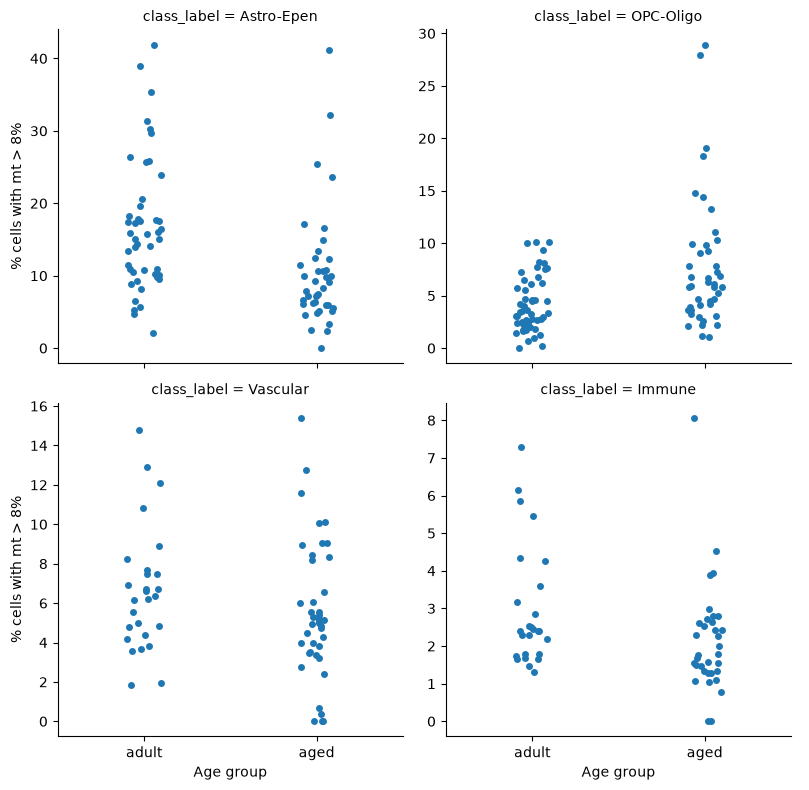

In [21]:
g = sns.catplot(
    data=mt_focus_plot,
    x="age_cat",
    y="pct_mt_gt8",
    col="class_label",
    col_order=classes,
    kind="strip",
    jitter=True,
    col_wrap=2,
    height=4,
    sharey=False
)

g.set_axis_labels("Age group", "% cells with mt > 8%")
plt.tight_layout()

In [22]:
mt_focus.groupby(
    ["class_label", "age_cat"],
    observed=True
)["n_cells"].describe()

count         mean          std   min      25%     50%  \
class_label age_cat                                                           
Astro-Epen  adult     64.0  1531.703125  2563.862201   1.0    43.75   152.0   
            aged      44.0  3820.727273  2996.565572   6.0   279.25  4031.0   
Immune      adult     52.0   485.500000   737.569791   4.0     9.50    51.5   
            aged      44.0  1078.840909   867.427765   1.0    70.50  1237.5   
OPC-Oligo   adult     53.0  2198.150943  1474.566382  53.0  1150.00  1973.0   
            aged      44.0  3107.954545  2031.754826  37.0  1463.75  3204.5   
Vascular    adult     52.0   665.403846   980.088116   2.0    18.00    58.0   
            aged      44.0  1136.795455   868.216498  19.0   255.50  1201.5   

                         75%      max  
class_label age_cat                    
Astro-Epen  adult    2231.75   9530.0  
            aged     6095.25  10592.0  
Immune      adult     762.50   3180.0  
            aged     1663.75   3079.0  
OPC-Oligo   adult    3430.00   5071.0  
            aged     4448.50   9255.0  
Vascular    adult    1069.50   3111.0  
            aged     1882.00   2857.0

## 4. Define donor metadata and primary pseudobulk thresholds

In [23]:
donor_age = (
    adata.obs[
        [
            "external_donor_name",
            "age_cat"
        ]
    ]
    .drop_duplicates()
)

age_per_donor = (
    donor_age
    .groupby(
        "external_donor_name",
        observed=True
    )["age_cat"]
    .nunique()
)

print(
    "Donors belonging to >1 age group:"
)

print(
    age_per_donor[
        age_per_donor > 1
    ]
)

print(
    "\nDonors per age:"
)

print(
    donor_age["age_cat"]
    .value_counts()
)

Donors belonging to >1 age group:
Series([], Name: age_cat, dtype: int64)

Donors per age:
age_cat
adult    64
aged     44
Name: count, dtype: int64


In [24]:
print("Primary pseudobulk uses all cells (qc_fail is not excluded).")
print(f"MIN_CELLS={MIN_CELLS}, MIN_DONORS={MIN_DONORS}")

Primary pseudobulk uses all cells (qc_fail is not excluded).
MIN_CELLS=15, MIN_DONORS=2


## 5. Build primary donor × subclass pseudobulks

In [25]:
subclasses = (
    adata.obs["subclass_label"]
    .dropna()
    .unique()
)

print("Number of subclasses:", len(subclasses))

Number of subclasses: 172


In [26]:
assert (
    donor_age
    .groupby("external_donor_name")["age_cat"]
    .nunique()
    .max()
    == 1
)

donor_age_lookup = (
    donor_age
    .assign(
        external_donor_name=lambda x:
        x["external_donor_name"].astype(str)
    )
    .set_index("external_donor_name")["age_cat"]
    .astype(str)
    .to_dict()
)

In [27]:
summary_rows = []
used_pb_paths = set()

In [28]:
for i, subclass in enumerate(subclasses, start=1):

    print(f"\n[{i}/{len(subclasses)}] {subclass}")

    # ---------------------------------------------------------
    # 1. Identify all cells belonging to this subclass
    # ---------------------------------------------------------

    cell_mask = (
        adata.obs["subclass_label"] == subclass
    ).to_numpy()

    cell_idx = np.flatnonzero(cell_mask)

    print("  Cells:", len(cell_idx))

    if len(cell_idx) == 0:
        summary_rows.append({
            "subclass_label": subclass,
            "status": "no_cells"
        })
        continue


    # ---------------------------------------------------------
    # 2. Get donor identity for those cells
    # ---------------------------------------------------------

    donors_for_cells = (
        adata.obs.iloc[cell_idx]["external_donor_name"]
        .astype(str)
        .to_numpy()
    )


    # ---------------------------------------------------------
    # 3. Count cells per donor
    # ---------------------------------------------------------

    donor_counts = (
        pd.Series(donors_for_cells)
        .value_counts()
    )

    valid_donors = donor_counts[
        donor_counts >= MIN_CELLS
    ].index.to_numpy()

    print(
        f"  Donors with >= {MIN_CELLS} cells:",
        len(valid_donors)
    )

    if len(valid_donors) == 0:
        summary_rows.append({
            "subclass_label": subclass,
            "status": "no_donors_after_min_cells"
        })
        continue


    # ---------------------------------------------------------
    # 4. Pseudobulk each donor
    # ---------------------------------------------------------

    pb_rows = []
    pb_donors = []
    pb_n_cells = []

    for donor in valid_donors:

        donor_cell_idx = cell_idx[
            donors_for_cells == donor
        ]

        # Sum raw counts over all cells from this donor
        donor_counts_vector = np.asarray(
            adata.X[donor_cell_idx].sum(axis=0)
        ).ravel()

        pb_rows.append(donor_counts_vector)
        pb_donors.append(donor)
        pb_n_cells.append(len(donor_cell_idx))


    # ---------------------------------------------------------
    # 5. Construct pseudobulk matrix
    # ---------------------------------------------------------

    pb_matrix = np.vstack(pb_rows)

    pb_obs = pd.DataFrame({
        "external_donor_name": pb_donors,
        "n_cells": pb_n_cells
    })

    pb_obs["age_cat"] = (
        pb_obs["external_donor_name"]
        .map(donor_age_lookup)
    )

    pb_obs.index = pb_obs["external_donor_name"]


    # ---------------------------------------------------------
    # 6. Check donor numbers by age
    # ---------------------------------------------------------

    age_counts = (
        pb_obs["age_cat"]
        .value_counts()
    )

    n_adult = age_counts.get("adult", 0)
    n_aged = age_counts.get("aged", 0)

    print(
        f"  Adult donors: {n_adult} | "
        f"Aged donors: {n_aged}"
    )


    # ---------------------------------------------------------
    # 7. Require >= MIN_DONORS in both groups
    # ---------------------------------------------------------

    if (
        n_adult < MIN_DONORS
        or n_aged < MIN_DONORS
    ):
        summary_rows.append({
            "subclass_label": subclass,
            "n_cells": len(cell_idx),
            "n_pseudobulks": len(pb_obs),
            "n_adult": n_adult,
            "n_aged": n_aged,
            "status": "insufficient_donors"
        })

        del pb_rows, pb_matrix, pb_obs
        gc.collect()

        continue


    # ---------------------------------------------------------
    # 8. Convert pseudobulk counts to sparse matrix
    # ---------------------------------------------------------

    pb_matrix = sp.csr_matrix(
        pb_matrix,
        dtype=np.int64
    )


    # ---------------------------------------------------------
    # 9. Construct AnnData
    # ---------------------------------------------------------

    pb = ad.AnnData(
        X=pb_matrix,
        obs=pb_obs,
        var=adata.var.copy()
    )

    pb.obs["subclass_label"] = subclass


    # ---------------------------------------------------------
    # 10. Sanity checks
    # ---------------------------------------------------------

    assert pb.obs_names.is_unique
    assert pb.var_names.is_unique

    assert np.all(
        pb.X.data >= 0
    )

    print(
        "  Pseudobulk shape:",
        pb.shape
    )


    # ---------------------------------------------------------
    # 11. Safe filename
    # ---------------------------------------------------------

    safe_name = (
        str(subclass)
        .replace(" ", "_")
        .replace("/", "_")
        .replace("\\", "_")
    )


    # ---------------------------------------------------------
    # 12. Save pseudobulk AnnData
    # ---------------------------------------------------------

    outfile = (
        outdir
        / f"{safe_name}_pseudobulk.h5ad"
    )

    if outfile in used_pb_paths:
        raise ValueError(f"Duplicate pseudobulk filename: {outfile}")
    used_pb_paths.add(outfile)

    pb.write_h5ad(
        outfile,
        compression="gzip"
    )


    # ---------------------------------------------------------
    # 13. Record summary
    # ---------------------------------------------------------

    summary_rows.append({
        "subclass_label": subclass,
        "n_cells": len(cell_idx),
        "n_pseudobulks": pb.n_obs,
        "n_adult": n_adult,
        "n_aged": n_aged,
        "n_genes": pb.n_vars,
        "status": "saved",
        "file": str(outfile)
    })

    print("  Saved:", outfile)


    # ---------------------------------------------------------
    # 14. Free memory before next subclass
    # ---------------------------------------------------------

    del (
        pb,
        pb_matrix,
        pb_rows,
        pb_obs,
        cell_idx,
        donors_for_cells
    )

    gc.collect()


[1/172] STR D1 Gaba
  Cells: 21794
  Donors with >= 15 cells: 24
  Adult donors: 15 | Aged donors: 9
  Pseudobulk shape: (24, 32285)
  Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/pseudobulk_primary/STR_D1_Gaba_pseudobulk.h5ad

[2/172] Astro-TE NN
  Cells: 143086
  Donors with >= 15 cells: 67
  Adult donors: 31 | Aged donors: 36
  Pseudobulk shape: (67, 32285)
  Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/pseudobulk_primary/Astro-TE_NN_pseudobulk.h5ad

[3/172] Endo NN
  Cells: 51387
  Donors with >= 15 cells: 80
  Adult donors: 37 | Aged donors: 43
  Pseudobulk shape: (80, 32285)
  Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/pseudobulk_primary/Endo_NN_pseudobulk.h5ad

[4/172] Oligo NN
  Cells: 165157
  Donors with >= 15 cells: 97
  Adult donors: 53 | Aged donors: 44
  Pseudobulk shape: (97, 32285)
  Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_da

In [29]:
pb_summary = pd.DataFrame(summary_rows)

pb_summary

,subclass_label,n_cells,n_pseudobulks,n_adult,n_aged,n_genes,status,file
0,STR D1 Gaba,21794,24,15,9,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
1,Astro-TE NN,143086,67,31,36,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
2,Endo NN,51387,80,37,43,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
3,Oligo NN,165157,97,53,44,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
4,Peri NN,17172,66,25,41,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
...,...,...,...,...,...,...,...,...
167,AVPV-MEPO-SFO Tbr1 Glut,614,10,5,5,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
168,ADP-MPO Trp73 Glut,204,5,2,3,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
169,PVHd-DMH Lhx6 Gaba,149,4,1,3,NaN,insufficient_donors,NaN
170,L2/3 IT ENT Glut,5072,9,2,7,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...


In [30]:
pb_summary.to_csv(
    outdir / "pseudobulk_summary.csv",
    index=False
)

In [31]:
pb_summary["status"].value_counts()

status
saved                  157
insufficient_donors     15
Name: count, dtype: int64

In [32]:
pb_summary[
    pb_summary["subclass_label"]
    .isin(major_subclasses)
]

,subclass_label,n_cells,n_pseudobulks,n_adult,n_aged,n_genes,status,file
2,Endo NN,51387,80,37,43,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
3,Oligo NN,165157,97,53,44,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
5,Microglia NN,69101,74,35,39,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
7,OPC NN,88095,97,53,44,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...
17,Astro-NT NN,118086,67,37,30,32285.0,saved,/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-be...


In [33]:
saved = pb_summary.loc[pb_summary["status"] == "saved"]
if saved.empty:
    raise ValueError("No eligible pseudobulks were generated.")
pb_files = sorted(Path(f) for f in saved["file"])
pb_by_subclass = dict(zip(saved["subclass_label"], saved["file"]))
print("Number of pseudobulk files:", len(pb_files))

Number of pseudobulk files: 157


## 6. Pseudobulk QC

PCA is performed on pseudobulk samples, not on individual cells. Raw summed counts remain unchanged in the saved pseudobulk objects; normalization/log transformation is done only on temporary copies for exploratory PCA.

/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/jin_dea/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


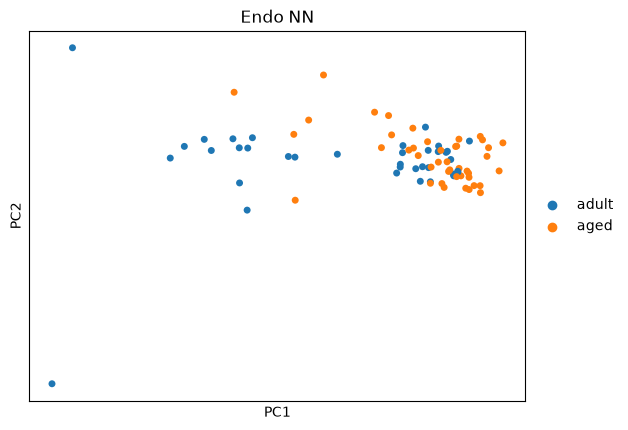

/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/jin_dea/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


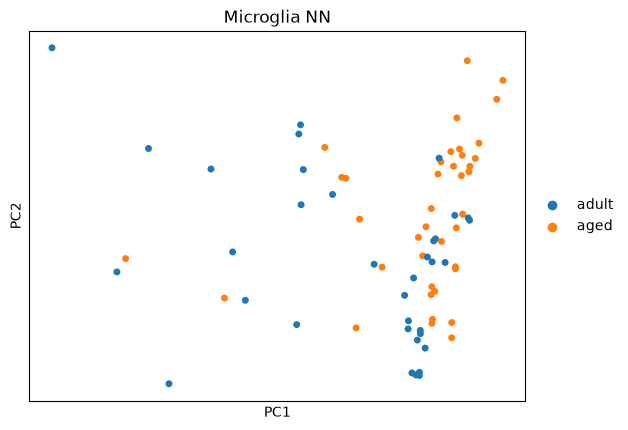

/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/jin_dea/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


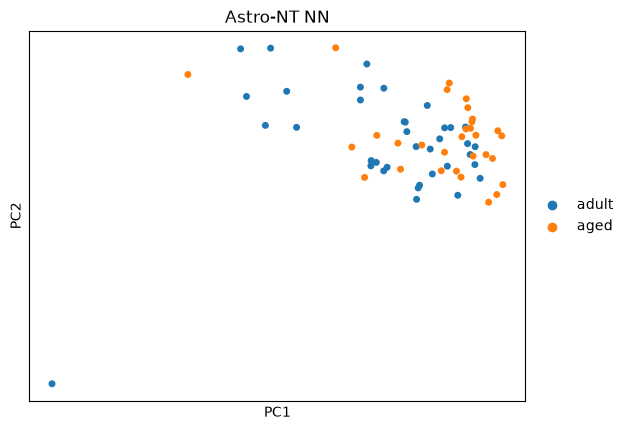

/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/jin_dea/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


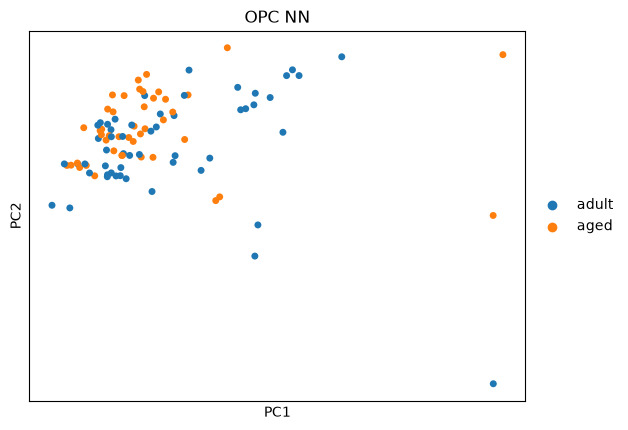

/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/Jin_count_data/jin_dea/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


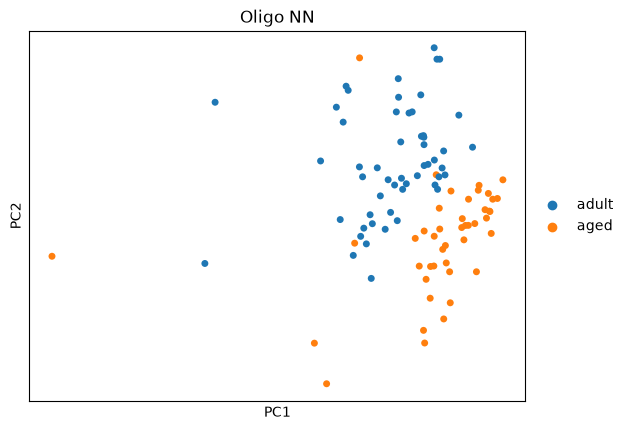

In [34]:
age_pc_results = []

for subclass in major_subclasses:

    if subclass not in pb_by_subclass:
        print(f"Skipping {subclass}: no eligible pseudobulk")
        continue
    file = pb_by_subclass[subclass]

    pb = sc.read_h5ad(file)

    X = pb.X

    n_samples_expressed = np.asarray(
        (X >= 10).sum(axis=0)
    ).ravel()

    keep = n_samples_expressed >= 5

    n_comps = min(10, pb.n_obs - 1, int(keep.sum()) - 1)
    if n_comps < 2:
        print(f"Skipping PCA for {subclass}: insufficient dimensions")
        continue
    pb_pca = pb[:, keep].copy()

    sc.pp.normalize_total(
        pb_pca,
        target_sum=1e6
    )

    sc.pp.log1p(pb_pca)
    sc.pp.scale(pb_pca, max_value=10)
    sc.tl.pca(pb_pca, n_comps=n_comps)

    sc.pl.pca(pb_pca, color="age_cat", size=100, title=subclass)

    pcs = pd.DataFrame(
        pb_pca.obsm["X_pca"][:, :10],
        index=pb_pca.obs_names,
        columns=[f"PC{i}" for i in range(1, n_comps + 1)]
    )

    pcs["age_cat"] = (
        pb_pca.obs["age_cat"]
        .astype(str)
        .values
    )

    for pc in [f"PC{i}" for i in range(1, n_comps + 1)]:

        adult = pcs.loc[
            pcs["age_cat"] == "adult",
            pc
        ]

        aged = pcs.loc[
            pcs["age_cat"] == "aged",
            pc
        ]

        _, p = mannwhitneyu(
            adult,
            aged,
            alternative="two-sided"
        )

        age_pc_results.append({
            "subclass_label": subclass,
            "PC": pc,
            "pvalue": p,
            "adult_mean": adult.mean(),
            "aged_mean": aged.mean()
        })

age_pc_results = pd.DataFrame(
    age_pc_results, columns=["subclass_label", "PC", "pvalue", "adult_mean", "aged_mean"]
)

In [35]:
age_pc_results.sort_values(
    "pvalue"
).head(30)

,subclass_label,PC,pvalue,adult_mean,aged_mean
34,OPC NN,PC5,6.695559e-16,-20.066660,24.171204
41,Oligo NN,PC2,1.348678e-09,22.639847,-27.270723
8,Endo NN,PC9,1.475714e-08,-8.758464,7.536353
40,Oligo NN,PC1,8.056974e-08,-16.091291,19.382692
12,Microglia NN,PC3,1.195211e-07,9.880366,-8.866995
43,Oligo NN,PC4,2.729684e-07,8.622097,-10.385709
6,Endo NN,PC7,6.072851e-07,9.360835,-8.054672
42,Oligo NN,PC3,1.098588e-06,-15.594765,18.784603
37,OPC NN,PC8,9.066028e-06,7.278941,-8.767816
39,OPC NN,PC10,2.678572e-05,-3.265851,3.933864


### Additional donor-level pseudobulk QC summary

In [36]:
# Summarize library size and contributing cell numbers for every saved pseudobulk file
pb_qc_rows = []

for file in pb_files:
    pb = sc.read_h5ad(file)
    lib_size = np.asarray(pb.X.sum(axis=1)).ravel()

    tmp = pb.obs[["external_donor_name", "age_cat", "n_cells"]].copy()
    tmp["subclass_label"] = pb.obs["subclass_label"].astype(str).values
    tmp["total_counts_pb"] = lib_size
    pb_qc_rows.append(tmp.reset_index(drop=True))

pb_qc = pd.concat(pb_qc_rows, ignore_index=True)

pb_qc.groupby(["subclass_label", "age_cat"], observed=True)[
    ["n_cells", "total_counts_pb"]
].describe()

n_cells                                        \
                             count        mean         std   min     25%   
subclass_label     age_cat                                                 
ABC NN             adult       3.0   73.333333   51.810552  15.0   53.00   
                   aged        7.0   34.285714   14.279522  17.0   23.00   
ADP-MPO Trp73 Glut adult       2.0   24.500000   10.606602  17.0   20.75   
                   aged        3.0   29.333333    2.516611  27.0   28.00   
AHN Onecut3 Gaba   adult       3.0   40.333333   21.079216  16.0   34.00   
...                            ...         ...         ...   ...     ...   
VMH Fezf1 Glut     aged        5.0   64.000000   24.217762  32.0   55.00   
VMH Nr5a1 Glut     adult       4.0  199.500000   94.108094  85.0  141.25   
                   aged        5.0  330.600000  198.087859  57.0  187.00   
Vip Gaba           adult      26.0  141.500000  155.074498  18.0   24.25   
                   aged       31.0  175.000000  145.919841  17.0   73.50   

                                                 total_counts_pb  \
                              50%     75%    max           count   
subclass_label     age_cat                                         
ABC NN             adult     91.0  102.50  114.0             3.0   
                   aged      34.0   44.00   55.0             7.0   
ADP-MPO Trp73 Glut adult     24.5   28.25   32.0             2.0   
                   aged      29.0   30.50   32.0             3.0   
AHN Onecut3 Gaba   adult     52.0   52.50   53.0             3.0   
...                           ...     ...    ...             ...   
VMH Fezf1 Glut     aged      62.0   73.00   98.0             5.0   
VMH Nr5a1 Glut     adult    216.0  274.25  281.0             4.0   
                   aged     439.0  453.00  517.0             5.0   
Vip Gaba           adult     88.0  206.50  536.0            26.0   
                   aged     148.0  215.50  566.0            31.0   

                                                                               \
                                    mean           std        min         25%   
subclass_label     age_cat                                                      
ABC NN             adult    1.244086e+06  8.865140e+05   290175.0   844792.00   
                   aged     4.804990e+05  1.664466e+05   284844.0   380869.50   
ADP-MPO Trp73 Glut adult    9.322320e+05  2.117841e+05   782478.0   857355.00   
                   aged     1.226355e+06  1.048873e+05  1147392.0  1166849.00   
AHN Onecut3 Gaba   adult    1.328319e+06  7.587306e+05   518265.0   981297.00   
...                                  ...           ...        ...         ...   
VMH Fezf1 Glut     aged     2.512628e+06  8.528084e+05  1465068.0  2331248.00   
VMH Nr5a1 Glut     adult    7.108484e+06  3.458106e+06  3088605.0  4935990.75   
                   aged     1.271726e+07  8.308935e+06  2615153.0  5255304.00   
Vip Gaba           adult    3.362484e+06  3.620918e+06   389984.0   625032.00   
                   aged     3.782298e+06  3.250903e+06   306104.0  1838447.50   

                                                                
                                   50%         75%         max  
subclass_label     age_cat                                      
ABC NN             adult     1399409.0   1721041.5   2042674.0  
                   aged       449995.0    572739.0    721437.0  
ADP-MPO Trp73 Glut adult      932232.0   1007109.0   1081986.0  
                   aged      1186306.0   1265836.0   1345366.0  
AHN Onecut3 Gaba   adult     1444329.0   1733346.5   2022364.0  
...                                ...         ...         ...  
VMH Fezf1 Glut     aged      2352057.0   2579813.0   3834956.0  
VMH Nr5a1 Glut     adult     7257419.5   9429912.5  10830491.0  
                   aged     15920220.0  18310279.0  21485353.0  
Vip Gaba           adult     1833991.5   4660736.5  12910837.0  
                   aged      

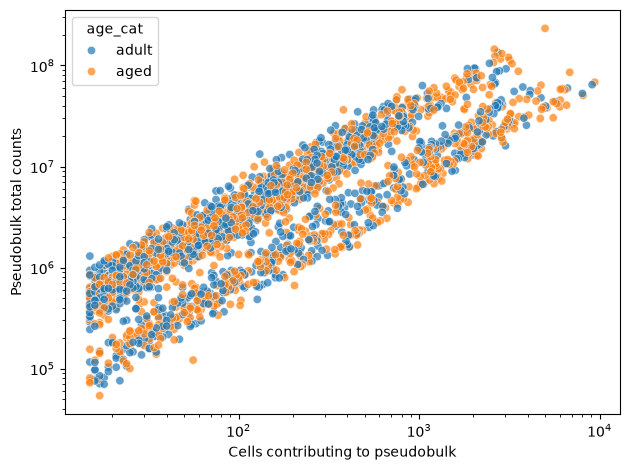

In [37]:
# Optional: inspect pseudobulk library size vs number of contributing cells
sns.scatterplot(
    data=pb_qc,
    x="n_cells",
    y="total_counts_pb",
    hue="age_cat",
    alpha=0.7
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Cells contributing to pseudobulk")
plt.ylabel("Pseudobulk total counts")
plt.tight_layout()
plt.show()

## 7. edgeR differential expression: aged vs adult

In [38]:
ro.r("""
suppressPackageStartupMessages({
    library(edgeR)
})
""")

print(ro.r("packageVersion('edgeR')"))

[1] ‘4.8.2’



In [39]:
ro.r(r"""
run_edger_age <- function(counts, metadata) {

    suppressPackageStartupMessages(library(edgeR))

    # adult = reference; aged = test
    metadata$age_cat <- factor(metadata$age_cat, levels = c("adult", "aged"))
    design <- model.matrix(~ age_cat, data = metadata)

    # Match the spatial edgeR workflow
    y <- DGEList(counts = counts, group = metadata$age_cat)
    genes_before <- nrow(y)

    keep <- filterByExpr(y, min.count = 2, design = design)
    y <- y[keep, , keep.lib.sizes = FALSE]
    genes_after <- nrow(y)

    # Jin has no spatial volume_sum equivalent: retain count-derived library sizes
    y <- calcNormFactors(y)

    # Same robust dispersion estimator and LRT framework as spatial analysis
    y <- estimateGLMRobustDisp(y, design)
    fit <- glmFit(y, design)
    lrt <- glmLRT(fit, coef = "age_cataged")

    result <- topTags(lrt, n = Inf, sort.by = "PValue")$table
    result$gene <- rownames(result)

    result <- result[, c("gene", "logFC", "logCPM", "LR", "PValue", "FDR")]

    return(list(
        results = result,
        genes_before = genes_before,
        genes_after = genes_after
    ))
}
""")

In [40]:
def run_edger_python(pb):

    # -----------------------------------------
    # Check metadata
    # -----------------------------------------

    if "age_cat" not in pb.obs.columns:
        raise ValueError(
            "age_cat is missing from pb.obs"
        )

    # -----------------------------------------
    # Counts:
    #
    # AnnData = samples × genes
    # edgeR   = genes × samples
    # -----------------------------------------

    counts = pd.DataFrame(
        pb.X.toarray().T,
        index=pb.var_names.astype(str),
        columns=pb.obs_names.astype(str)
    )

    # Make sure counts are integers
    counts = counts.astype(np.int64)

    # -----------------------------------------
    # Metadata
    # -----------------------------------------

    metadata = pd.DataFrame(
        {
            "age_cat":
                pb.obs["age_cat"]
                .astype(str)
                .values
        },
        index=pb.obs_names.astype(str)
    )

    # -----------------------------------------
    # Check ordering
    # -----------------------------------------

    assert np.array_equal(
        counts.columns,
        metadata.index
    )

    # -----------------------------------------
    # Convert Python -> R
    # -----------------------------------------

    with localconverter(
        ro.default_converter
        + pandas2ri.converter
    ):

        r_counts = ro.conversion.py2rpy(
            counts
        )

        r_metadata = ro.conversion.py2rpy(
            metadata
        )

    # -----------------------------------------
    # Run edgeR
    # -----------------------------------------

    r_output = ro.globalenv[
        "run_edger_age"
    ](
        r_counts,
        r_metadata
    )

    # -----------------------------------------
    # Extract result table
    # -----------------------------------------

    r_results = r_output.rx2(
        "results"
    )

    with localconverter(
        ro.default_converter
        + pandas2ri.converter
    ):

        results = ro.conversion.rpy2py(
            r_results
        )

    results = pd.DataFrame(
        results
    )

    # -----------------------------------------
    # Other information
    # -----------------------------------------

    genes_before = int(
        r_output.rx2(
            "genes_before"
        )[0]
    )

    genes_after = int(
        r_output.rx2(
            "genes_after"
        )[0]
    )

    return (
        results,
        genes_before,
        genes_after
    )

In [41]:
summary_rows = []
result_files = []

for i, file in enumerate(
    pb_files,
    start=1
):

    subclass = (
        file.stem
        .replace(
            "_pseudobulk",
            ""
        )
    )

    print(
        f"\n[{i}/{len(pb_files)}] "
        f"{subclass}"
    )

    try:

        # -------------------------------------
        # Load pseudobulk
        # -------------------------------------

        pb = sc.read_h5ad(
            file
        )

        subclass = str(pb.obs["subclass_label"].iloc[0])
        if pb.obs["subclass_label"].nunique() != 1:
            raise ValueError("Expected exactly one subclass per pseudobulk")

        # -------------------------------------
        # Check age groups
        # -------------------------------------

        age_counts = (
            pb.obs["age_cat"]
            .astype(str)
            .value_counts()
        )

        n_adult = int(
            age_counts.get(
                "adult",
                0
            )
        )

        n_aged = int(
            age_counts.get(
                "aged",
                0
            )
        )

        print(
            f"  adult = {n_adult}, "
            f"aged = {n_aged}"
        )

        # -------------------------------------
        # Safety check
        # -------------------------------------

        if (
            n_adult < MIN_DONORS
            or
            n_aged < MIN_DONORS
        ):

            print(
                "  skipped: "
                "insufficient donors"
            )

            summary_rows.append(
                {
                    "subclass_label":
                        subclass,

                    "n_adult":
                        n_adult,

                    "n_aged":
                        n_aged,

                    "status":
                        "insufficient_donors"
                }
            )

            del pb
            gc.collect()

            continue


        # -------------------------------------
        # Run edgeR
        # -------------------------------------

        (
            results,
            genes_before,
            genes_after
        ) = run_edger_python(pb)


        # -------------------------------------
        # Add annotations
        # -------------------------------------

        results[
            "subclass_label"
        ] = subclass

        results[
            "direction"
        ] = np.where(
            results["logFC"] > 0,
            "higher_in_aged",
            "higher_in_adult"
        )

        results[
            "significant_FDR05"
        ] = (
            results["FDR"] < 0.05
        )


        # -------------------------------------
        # Number of significant genes
        # -------------------------------------

        n_deg = int(
            results[
                "significant_FDR05"
            ].sum()
        )

        n_up = int(
            (
                results[
                    "significant_FDR05"
                ]
                &
                (
                    results["logFC"]
                    > 0
                )
            ).sum()
        )

        n_down = int(
            (
                results[
                    "significant_FDR05"
                ]
                &
                (
                    results["logFC"]
                    < 0
                )
            ).sum()
        )


        # -------------------------------------
        # Save subclass result
        # -------------------------------------

        outfile = (
            RESULT_DIR
            / (
                f"{file.stem.removesuffix('_pseudobulk')}"
                "_edgeR_results.csv"
            )
        )

        results.to_csv(
            outfile,
            index=False
        )


        result_files.append(outfile)

        # -------------------------------------
        # Summary
        # -------------------------------------

        summary_rows.append(
            {
                "subclass_label":
                    subclass,

                "n_adult":
                    n_adult,

                "n_aged":
                    n_aged,

                "genes_before_filter":
                    genes_before,

                "genes_after_filter":
                    genes_after,

                "n_DEG_FDR05":
                    n_deg,

                "n_higher_in_aged":
                    n_up,

                "n_higher_in_adult":
                    n_down,

                "status":
                    "completed"
            }
        )


        print(
            f"  genes: "
            f"{genes_before} -> "
            f"{genes_after}"
        )

        print(
            f"  DEGs: {n_deg}"
        )

        print(
            f"    higher aged: {n_up}"
        )

        print(
            f"    higher adult: {n_down}"
        )


        # -------------------------------------
        # Free memory
        # -------------------------------------

        del pb, results

        gc.collect()


    except Exception as e:

        print(
            "  FAILED:",
            str(e)
        )

        summary_rows.append(
            {
                "subclass_label":
                    subclass,

                "status":
                    "failed",

                "error":
                    str(e)
            }
        )

        try:
            del pb
        except NameError:
            pass

        gc.collect()


[1/157] ABC_NN
  adult = 3, aged = 7
  genes: 32285 -> 12451
  DEGs: 95
    higher aged: 53
    higher adult: 42

[2/157] ADP-MPO_Trp73_Glut
  adult = 2, aged = 3
  genes: 32285 -> 12777
  DEGs: 158
    higher aged: 62
    higher adult: 96

[3/157] AHN-RCH-LHA_Otp_Fezf1_Glut
  adult = 4, aged = 5
  genes: 32285 -> 15432
  DEGs: 263
    higher aged: 130
    higher adult: 133

[4/157] AHN-SBPV-PVHd_Pdrm12_Gaba
  adult = 4, aged = 5
  genes: 32285 -> 16083
  DEGs: 244
    higher aged: 142
    higher adult: 102

[5/157] AHN_Onecut3_Gaba
  adult = 3, aged = 5
  genes: 32285 -> 15052
  DEGs: 59
    higher aged: 33
    higher adult: 26

[6/157] ARH-PVi_Six6_Dopa-Gaba
  adult = 2, aged = 4
  genes: 32285 -> 12967
  DEGs: 87
    higher aged: 26
    higher adult: 61

[7/157] ARH-PVp_Tbx3_Gaba
  adult = 4, aged = 5
  genes: 32285 -> 16057
  DEGs: 489
    higher aged: 234
    higher adult: 255

[8/157] ARH-PVp_Tbx3_Glut
  adult = 4, aged = 5
  genes: 32285 -> 16929
  DEGs: 205
    higher aged: 83

In [42]:
edgeR_summary = pd.DataFrame(
    summary_rows
)

edgeR_summary

,subclass_label,n_adult,n_aged,genes_before_filter,genes_after_filter,n_DEG_FDR05,n_higher_in_aged,n_higher_in_adult,status
0,ABC NN,3,7,32285,12451,95,53,42,completed
1,ADP-MPO Trp73 Glut,2,3,32285,12777,158,62,96,completed
2,AHN-RCH-LHA Otp Fezf1 Glut,4,5,32285,15432,263,130,133,completed
3,AHN-SBPV-PVHd Pdrm12 Gaba,4,5,32285,16083,244,142,102,completed
4,AHN Onecut3 Gaba,3,5,32285,15052,59,33,26,completed
...,...,...,...,...,...,...,...,...,...
152,Tanycyte NN,11,5,32285,15577,1067,728,339,completed
153,VLMC NN,21,34,32285,13803,597,285,312,completed
154,VMH Fezf1 Glut,3,5,32285,15364,89,27,62,completed
155,VMH Nr5a1 Glut,4,5,32285,18431,666,332,334,completed


In [43]:
edgeR_summary.to_csv(
    RESULT_DIR
    / "edgeR_analysis_summary.csv",
    index=False
)

In [44]:
(
    edgeR_summary
    .query(
        "status == 'completed'"
    )
    .sort_values(
        "n_DEG_FDR05",
        ascending=False
    )
    .head(30)
)

,subclass_label,n_adult,n_aged,genes_before_filter,genes_after_filter,n_DEG_FDR05,n_higher_in_aged,n_higher_in_adult,status
87,Oligo NN,53,44,32285,18259,9237,4945,4292,completed
78,Microglia NN,35,39,32285,16617,6505,3295,3210,completed
86,OPC NN,53,44,32285,18143,6377,3482,2895,completed
33,Endo NN,37,43,32285,15455,4572,2521,2051,completed
141,STR D1 Gaba,15,9,32285,19173,3935,2231,1704,completed
10,Astro-TE NN,31,36,32285,18844,3750,2081,1669,completed
50,L4 RSP-ACA Glut,3,5,32285,17091,2837,1303,1534,completed
143,STR D2 Gaba,20,10,32285,17785,2831,1788,1043,completed
125,Peri NN,25,41,32285,14093,2271,1210,1061,completed
9,Astro-NT NN,37,30,32285,13512,2125,1015,1110,completed


## 8. Combine and validate current-run results
Only successfully generated files from this run are combined. Failed subclasses are recorded in the analysis summary.

In [45]:
if not result_files:
    raise RuntimeError("No edgeR analyses completed successfully.")
all_results = pd.concat(
    [
        pd.read_csv(f)
        for f in result_files
    ],
    ignore_index=True
)

if all_results["LR"].isna().any():
    raise ValueError("Missing LRT statistics in current edgeR results")
if all_results.duplicated(["gene", "subclass_label"]).any():
    raise ValueError("Duplicate gene–subclass results detected; inspect current result files.")
print(all_results.shape)

all_results.head()

(2480312, 9)


,gene,logFC,logCPM,LR,PValue,FDR,subclass_label,direction,significant_FDR05
0,Ccnd2,-1.956826,6.696905,91.120310,1.351969e-21,1.683336e-17,ABC NN,higher_in_adult,True
1,H2-Ab1,1.940975,5.652563,71.432115,2.869632e-17,1.786489e-13,ABC NN,higher_in_aged,True
2,Mybpc1,3.537101,4.830414,50.896158,9.738399e-13,4.041760e-09,ABC NN,higher_in_aged,True
3,C130026I21Rik,4.349062,5.026137,49.759460,1.737982e-12,5.409904e-09,ABC NN,higher_in_aged,True
4,H2-Aa,2.241838,6.273814,48.743097,2.917837e-12,7.265998e-09,ABC NN,higher_in_aged,True


In [46]:
all_results.to_csv(
    RESULT_DIR
    / "all_subclasses_edgeR_results.csv",
    index=False
)

In [47]:
significant_results = (
    all_results[
        all_results["FDR"] < 0.05
    ]
    .copy()
)

print(
    "Total significant "
    "subclass-gene associations:",
    len(significant_results)
)

Total significant subclass-gene associations: 98841


## 9. Differential expression visualisations

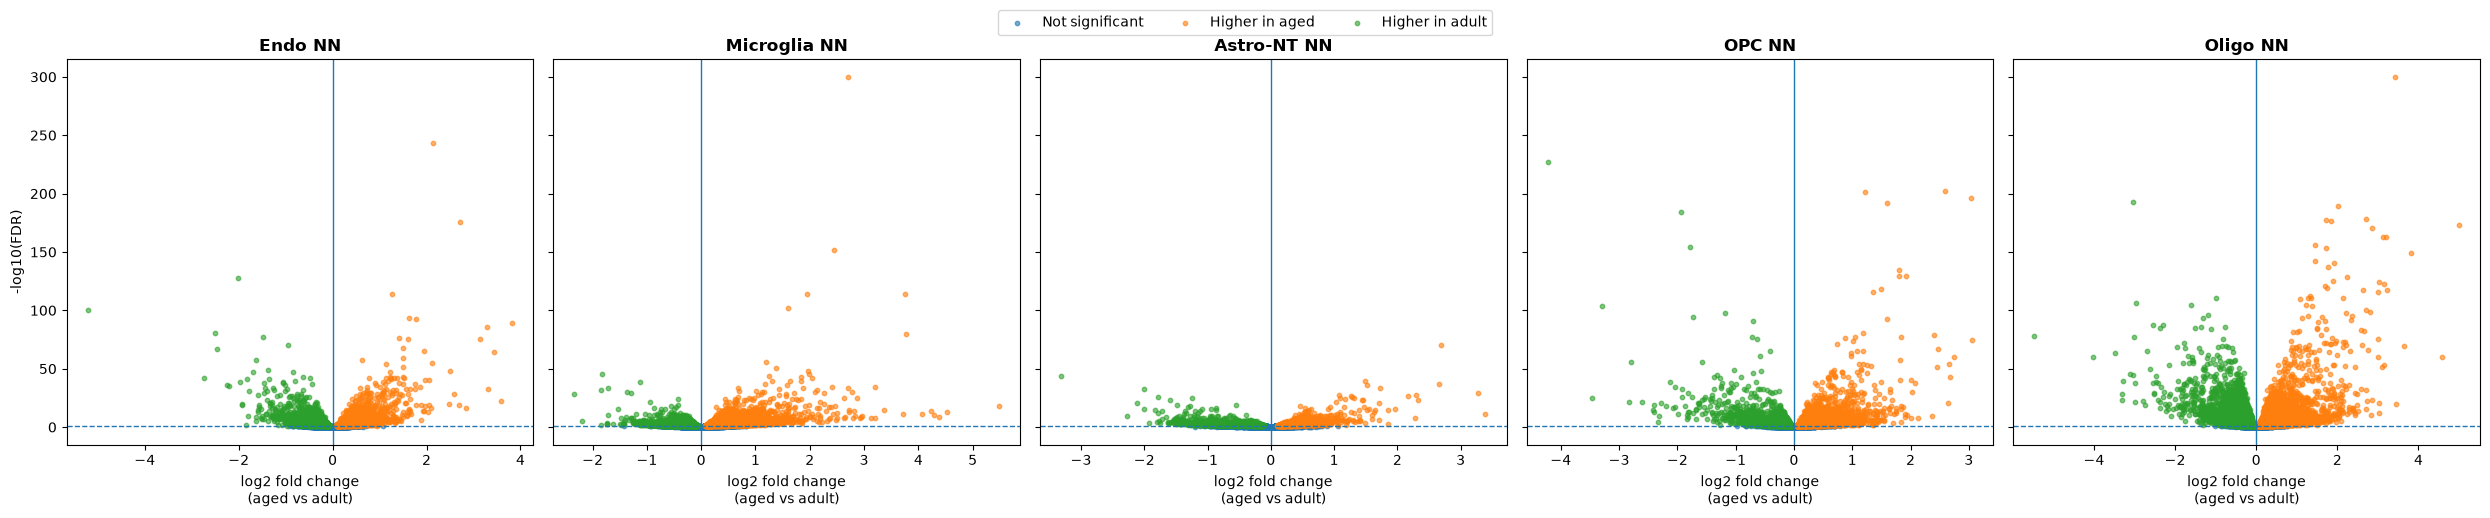

In [48]:
fig, axes = plt.subplots(
    1,
    len(major_subclasses),
    figsize=(5 * len(major_subclasses), 5),
    sharey=True
)

for ax, subclass in zip(
    axes,
    major_subclasses
):

    df = all_results[
        all_results["subclass_label"] == subclass
    ].copy()

    df["minus_log10_FDR"] = (
        -np.log10(
            df["FDR"].clip(lower=1e-300)
        )
    )

    df["significance"] = "Not significant"

    df.loc[
        (df["FDR"] < 0.05)
        & (df["logFC"] > 0),
        "significance"
    ] = "Higher in aged"

    df.loc[
        (df["FDR"] < 0.05)
        & (df["logFC"] < 0),
        "significance"
    ] = "Higher in adult"

    for group in [
        "Not significant",
        "Higher in aged",
        "Higher in adult"
    ]:

        x = df[
            df["significance"] == group
        ]

        ax.scatter(
            x["logFC"],
            x["minus_log10_FDR"],
            s=10,
            alpha=0.6,
            label=group
        )

    ax.axhline(
        -np.log10(0.05),
        linestyle="--",
        linewidth=1
    )

    ax.axvline(
        0,
        linewidth=1
    )

    ax.set_title(
        subclass,
        fontweight="bold"
    )

    ax.set_xlabel(
        "log2 fold change\n(aged vs adult)"
    )

axes[0].set_ylabel(
    "-log10(FDR)"
)

handles, labels = axes[-1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=3
)

plt.tight_layout()
plt.savefig(f"{outdir}/vulcanos.pdf", bbox_inches="tight")
plt.show()

In [49]:
major_results = all_results[
    all_results["subclass_label"]
    .isin(major_subclasses)
].copy()

major_results["direction"] = np.where(
    major_results["logFC"] > 0,
    "Higher in aged",
    "Higher in adult"
)

deg_counts = (
    major_results[
        major_results["FDR"] < 0.05
    ]
    .groupby(
        [
            "subclass_label",
            "direction"
        ]
    )
    .size()
    .reset_index(
        name="n_genes"
    )
)

deg_counts

,subclass_label,direction,n_genes
0,Astro-NT NN,Higher in adult,1110
1,Astro-NT NN,Higher in aged,1015
2,Endo NN,Higher in adult,2051
3,Endo NN,Higher in aged,2521
4,Microglia NN,Higher in adult,3210
5,Microglia NN,Higher in aged,3295
6,OPC NN,Higher in adult,2895
7,OPC NN,Higher in aged,3482
8,Oligo NN,Higher in adult,4292
9,Oligo NN,Higher in aged,4945


In [50]:
deg_counts["plot_count"] = (
    deg_counts["n_genes"]
)

deg_counts.loc[
    deg_counts["direction"] == "Higher in adult",
    "plot_count"
] *= -1

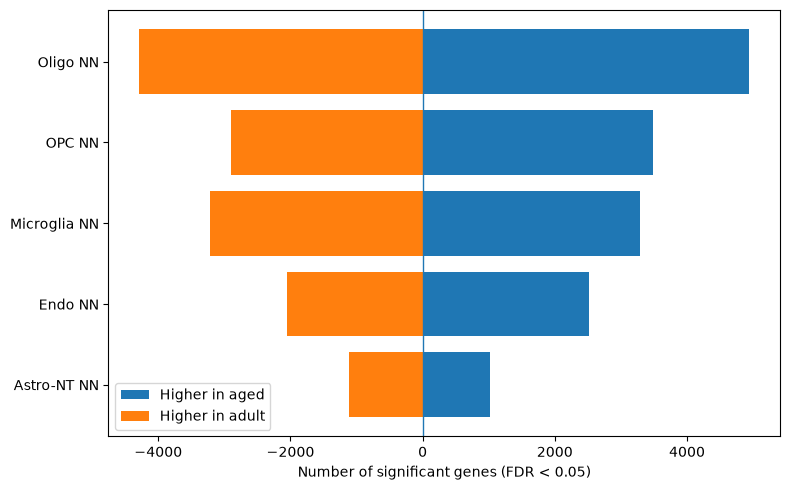

In [51]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

for direction in [
    "Higher in aged",
    "Higher in adult"
]:

    df = deg_counts[
        deg_counts["direction"] == direction
    ]

    ax.barh(
        df["subclass_label"],
        df["plot_count"],
        label=direction
    )

ax.axvline(
    0,
    linewidth=1
)

ax.set_xlabel(
    "Number of significant genes (FDR < 0.05)"
)

ax.set_ylabel("")

ax.legend()

plt.tight_layout()
plt.savefig(f"{outdir}/significant_genes.pdf", bbox_inches="tight")
plt.show()

In [52]:
N_TOP_GENES = 50

top_genes = (
    major_results
    .assign(abs_logFC=major_results["logFC"].abs())
    .groupby("gene", as_index=False)["abs_logFC"]
    .max()
    .nlargest(N_TOP_GENES, "abs_logFC")["gene"]
    .tolist()
)

print(f"Selected {len(top_genes)} top genes")

Selected 50 top genes


In [53]:
# logFC matrix
logfc_matrix = (
    major_results[
        major_results["gene"].isin(top_genes)
    ]
    .pivot(
        index="gene",
        columns="subclass_label",
        values="logFC"
    )
)

# FDR matrix
fdr_matrix = (
    major_results[
        major_results["gene"].isin(top_genes)
    ]
    .pivot(
        index="gene",
        columns="subclass_label",
        values="FDR"
    )
)

# Make sure both matrices have identical ordering
fdr_matrix = fdr_matrix.reindex(
    index=logfc_matrix.index,
    columns=logfc_matrix.columns
)

print("logFC matrix:", logfc_matrix.shape)
print("FDR matrix:", fdr_matrix.shape)

logFC matrix: (50, 5)
FDR matrix: (50, 5)


In [54]:
mask = (
    fdr_matrix >= 0.05
)

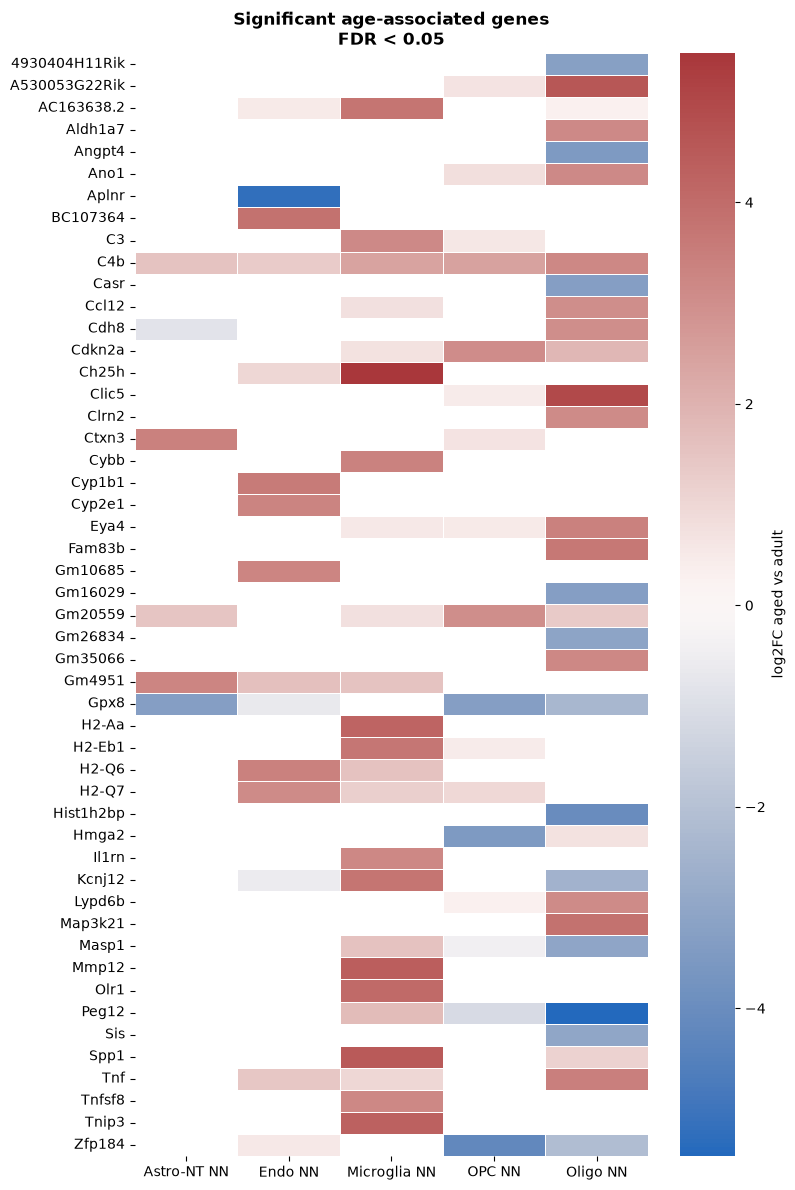

In [55]:
plt.figure(
    figsize=(8, 12)
)

sns.heatmap(
    logfc_matrix,
    mask=mask,
    center=0,
    cmap="vlag",
    linewidths=0.5,
    cbar_kws={
        "label": "log2FC aged vs adult"
    }
)

plt.xlabel("")
plt.ylabel("")

plt.title(
    "Significant age-associated genes\nFDR < 0.05",
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(f"{outdir}/heatmap.pdf", bbox_inches="tight")
plt.show()

In [56]:
shared_deg = (
    major_results[
        major_results["FDR"] < 0.05
    ]
    .groupby("gene")
    .agg(
        n_subclasses=(
            "subclass_label",
            "nunique"
        ),
        mean_logFC=(
            "logFC",
            "mean"
        )
    )
    .sort_values(
        "n_subclasses",
        ascending=False
    )
)

shared_deg.head(30)

,n_subclasses,mean_logFC
gene,,
Kifc3,5,0.075838
Mycl,5,-0.884253
Per3,5,0.409043
Ifit1,5,1.281789
Phf1,5,0.297964
Elfn2,5,-0.572314
Rcan2,5,0.344368
Cldn11,5,-0.867937
Dcc,5,-0.699221


## Optional analyses
The separate UMAP notebook contains the original single-cell visualisations. 